# Project 1: Sentiment classification on SST-2

In this project we classify movie-review phrases from SST-2 as negative or positive. We compare 3 ways of representing the text with 3 model architectures, which gives 9 systems in total. We compare them with cross-validation and then use Bayesian estimation with a ROPE for analysis.

| Representations | Architectures |
|---|---|
| token indicators | log-linear |
| bag-of-words | single-hidden-layer MLP |
| TF-IDF (extra) | two-hidden-layer MLP (extra) |

## 1. Setup

In [3]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

import sys
from pathlib import Path

# Assuming the working directory is root/part1
root = Path.cwd().parent
sys.path.insert(0, str(root))

import part1

import os
import pickle
import itertools
from collections import OrderedDict

import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from tokenizers import Tokenizer
from part1.clslib import Encoder

results_folder = Path("./results")
results_folder.mkdir(parents=True, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(max(1, (os.cpu_count() or 2) - 1))
device

'cpu'

## 2. Data and metric

We only use the `train` split of SST-2 (67,349 labelled phrases). The `test` split has no labels (they are all -1) and the `validation` split only has 872 phrases, which is too small to get reliable scores. That is why we do cross-validation on `train`.

We use accuracy as our metric. The two classes are close to balanced (about 56% positive), so accuracy is a fair measure here. As a reference point we also compute the majority-class baseline: the accuracy you get by always predicting "positive", without reading the text.

In [5]:
sst2_outcome_space = part1.clslib.NamedClasses(['negative', 'positive'])
dataset = load_dataset("stanfordnlp/sst2")
print(dataset)

corpus = dataset["train"]["sentence"]
labels = np.array(dataset["train"]["label"])

print("Example:", corpus[0], "->", sst2_outcome_space.name(labels[0]))
print("Label counts:", {sst2_outcome_space.name(k): int(v) for k, v in zip(*np.unique(labels, return_counts=True))})
print(f"Majority-class baseline accuracy: {max(np.mean(labels), 1 - np.mean(labels)):.4f}")
print("Median length (words):", int(np.median([len(s.split()) for s in corpus])))

DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})
Example: hide new secretions from the parental units  -> negative
Label counts: {'negative': 29780, 'positive': 37569}
Majority-class baseline accuracy: 0.5578
Median length (words): 7


## 3. Tokenizer: BPE

We use the BPE tokenizer from the tutorial with `vocab_size=1000` and `min_frequency=2`, and all systems share the same one. We train it once on the training sentences. Since BPE never looks at the labels, we did not retrain it for every fold.

In [7]:
vocab_size = 1000
min_frequency = 2
tokenizer = part1.experiment.train_tokenizer(corpus, vocab_size, min_frequency)
tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

print(tokenizer.encode("the performances are intelligent and joyful").tokens)




['▁the', '▁performances', '▁are', '▁intellig', 'ent', '▁and', '▁j', 'oy', 'ful']


## 4. Representations

Every encoder turns a text into a vector with one entry per BPE token (1000 dimensions):

* **Token indicators:** 1 if the token appears in the text, 0 if it does not.
* **Bag-of-words:** the number of times each token appears.
* **TF-IDF (extra):** the counts, multiplied by how rare the token is across the training set, `idf = log((1+N)/(1+df)) + 1`. After that we normalise the vector to length 1. This way very common tokens like `▁the` count less and rarer tokens count more. We compute the IDF once in `__init__`, and the counts for each text in `__call__`.

In [9]:
class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector


class BagOfWords(TokenIndicator):

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of token counts"""
        vector = np.zeros(len(self))
        # count every occurrence (vector[ids] += 1 would add only once per repeated id)
        for token_id in self.tokenizer.encode(x).ids:
            vector[token_id] += 1
        return vector


class TFIDF(Encoder):

    def __init__(self, tokenizer: Tokenizer, corpus: list):
        self.tokenizer = tokenizer
        document_frequency = np.zeros(len(self))

        # Document frequency
        for sentence in corpus:
            unique_token_ids = list(set(self.tokenizer.encode(sentence).ids))
            document_frequency[unique_token_ids] += 1

        # Inverse document frequency
        N = len(corpus)
        self.idf = np.log((1 + N) / (1 + document_frequency)) + 1

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        token_ids = self.tokenizer.encode(x).ids

        vector = np.zeros(len(self))

        # Term frequency
        for token_id in token_ids:
            vector[token_id] += 1

        # TF-IDF
        vector = vector * self.idf
        norm = np.linalg.norm(vector)
        if norm:
            vector = vector / norm
        return vector

In [10]:
encoders = OrderedDict([
    ("indicator", TokenIndicator(tokenizer)),
    ("bow", BagOfWords(tokenizer)),
    ("TFIDF", TFIDF(tokenizer, corpus)),
])

# sanity check: a text with repeated tokens must look different under each encoder
example = "the plot , the actors , the music"
the_id = tokenizer.token_to_id("▁the")
for name, encoder in encoders.items():
    v = encoder(example)
    print(f"{name:10s} dim={len(v)}  value for '▁the'={v[the_id]:.3f}  sum={v.sum():.3f}")

indicator  dim=1000  value for '▁the'=1.000  sum=5.000
bow        dim=1000  value for '▁the'=3.000  sum=8.000
TFIDF      dim=1000  value for '▁the'=0.501  sum=2.219


## 5. Architectures

All three models get the encoded text h(x), output a probability for each of the 2 classes and predict the most probable one.

* **Log-linear:** `p(y|x) = softmax(W h(x) + b)`, using `LogisticRegression` from sklearn like in the tutorial (`part1.loglin`). We kept the default settings: L2 regularisation with C = 1.0, `saga` solver, `max_iter=100`.
* **Single-hidden-layer MLP:** `h(x) → Linear(1000→128) → ReLU → Dropout → Linear(128→2) → softmax` (`part1.smlp.SparseMLP`).
* **Two-hidden-layer MLP, "mmlp" (extra):** the same, but with a second hidden layer of 64 units (`part1.smlp.SparseMMLP`).

The MLPs use the training settings from the tutorial: AdamW, learning rate 1e-4, weight decay 1e-4, batch size 64, 10 epochs, and we keep the epoch with the lowest validation loss. We pick the dropout rate with nested CV: inside each training fold, we try dropout 0, 0.05, 0.1, 0.2 and 0.3 on an inner split, choose the one with the lowest validation loss, and then train that model on the whole training fold. We did not tune anything for the log-linear model.

## 6. Cross-validation

We use 5-fold cross-validation and repeat it 3 times with different shuffles (seeds 0, 3 and 5), so every system gets 15 accuracy scores. In each fold the model is trained from scratch on 4/5 of the data and tested on the remaining 1/5.

In [13]:
my_seeds = [0, 3, 5]
num_folds = 5
my_cross_validation_sets = []

for seed in my_seeds:
    my_cross_validation_sets.append(
        part1.experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(corpus, dataset["train"]["label"])),
            k=num_folds,
            seed=seed
        )
    )

param_grid = {
    "dropout": [0, 0.05, 0.1, 0.2, 0.3]
}

smlp_args = {
    'hidden_dim': 128,
    'dropout': 0.1,
    'batch_size': 64,
    'learning_rate': 1e-4,
    'weight_decay': 1e-4,
    'num_epochs': 10,
    'device': device
}


def total_train(name, model_option, encoder):
    """Run the cross-validation experiment (all seeds) for one system and store it in my_classifiers[name]"""
    my_classifiers[name] = []
    for run, seed in enumerate(my_seeds):
        run_folder = f"{results_folder}/{name}/seed-{seed}"
        my_classifiers[name].append(
            part1.experiment.cross_validation_experiment(
                encoder=encoder,
                data_splits=my_cross_validation_sets[run],
                outcome_space=sst2_outcome_space,
                model_option=model_option,
                save_to=run_folder,
                param_grid=param_grid,  # only used by the MLPs
                smlp_args=smlp_args,
            )
        )

### Training (or loading saved results)

Training all 9 systems takes several hours, mostly because of the nested CV for the MLPs (a GPU helps a lot). We saved the results in `results/my_classifiers.pkl`, so by default this cell just loads them. If you want to retrain a system, add it to `to_train`, or use `list(itertools.product(["logistic", "mlp", "mmlp"], encoders))` to retrain all 9.

In [15]:
results_file = results_folder / "my_classifiers.pkl"

my_classifiers = OrderedDict()
if results_file.exists():
    with open(results_file, "rb") as f:
        my_classifiers = pickle.load(f)

to_train = []  # e.g. [("logistic", "bow"), ("mlp", "bow"), ("mmlp", "bow")]

for model_option, name in to_train:
    total_train(f"{model_option}-{name}", model_option, encoders[name])

if to_train:
    with open(results_file, "wb") as f:
        pickle.dump(my_classifiers, f)

# keep a fixed order: logistic, mlp, mmlp × indicator, bow, TFIDF
order = [f"{m}-{e}" for m in ["logistic", "mlp", "mmlp"] for e in encoders]
my_classifiers = OrderedDict((name, my_classifiers[name]) for name in order if name in my_classifiers)
list(my_classifiers)

['logistic-indicator',
 'logistic-bow',
 'logistic-TFIDF',
 'mlp-indicator',
 'mlp-bow',
 'mlp-TFIDF',
 'mmlp-indicator',
 'mmlp-bow',
 'mmlp-TFIDF']

In [16]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

## 7. Results

In [18]:
summary = pd.DataFrame([
    {
        "system": name,
        "mean accuracy": get_all_measurements_for(my_classifiers, name).mean(),
        "std": get_all_measurements_for(my_classifiers, name).std(ddof=1),
        "min": get_all_measurements_for(my_classifiers, name).min(),
        "max": get_all_measurements_for(my_classifiers, name).max(),
    }
    for name in my_classifiers
]).sort_values("mean accuracy", ascending=False).round(4)
summary

,system,mean accuracy,std,min,max
6,mmlp-indicator,0.8905,0.0029,0.8854,0.8955
7,mmlp-bow,0.8894,0.0038,0.8849,0.8962
8,mmlp-TFIDF,0.8620,0.0060,0.8537,0.8713
4,mlp-bow,0.8348,0.0037,0.8272,0.8433
3,mlp-indicator,0.8320,0.0048,0.8215,0.8401
5,mlp-TFIDF,0.7931,0.0035,0.7841,0.7971
2,logistic-TFIDF,0.7846,0.0032,0.7767,0.7888
1,logistic-bow,0.7826,0.0031,0.7768,0.7902
0,logistic-indicator,0.7815,0.0029,0.7757,0.7878


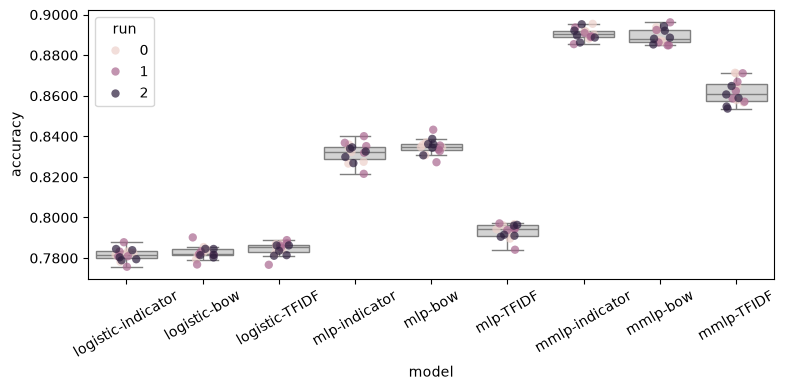

In [19]:
part1.analysis.plot_box_and_points(part1.analysis.make_data_frame(my_classifiers))

## 8. Bayesian estimation with a ROPE

To compare two systems A and B, we use the correlated t-test of Benavoli et al. (2017) (`part1.analysis.BenavoliCorrelatedT`). It gives us a distribution over the difference in mean accuracy (B − A). We need the correlated version because the folds share training data, so their scores are not independent. We set `runs=3` because our 15 scores come from 3 repetitions of 5-fold CV.

We chose a ROPE of 0.005, i.e. half an accuracy point. If the difference falls inside (−0.005, 0.005), we treat the two systems as equally good. On a validation fold of about 13.5k phrases, 0.005 is about 67 phrases. That is also roughly how much the accuracy of one system varies between folds (std of about 0.003 to 0.006), so we do not think smaller differences mean much.

For every pair we report P(A wins), P(tie), which is the chance that the difference is inside the ROPE, and P(B wins).

In [21]:
rope = 0.005

rows = []
for pa, pb in itertools.combinations(my_classifiers, 2):
    posterior = part1.analysis.BenavoliCorrelatedT(
        get_all_measurements_for(my_classifiers, pa).flatten(),  # this will have shape [num_runs * num_folds]
        get_all_measurements_for(my_classifiers, pb).flatten(),  # this will have shape [num_runs * num_folds]
        runs=len(my_seeds),
        names=[pa, pb]
    )
    p_a, p_tie, p_b = posterior.probs(rope)
    rows.append({"A": pa, "B": pb, "mean diff (B-A)": posterior.mean_diff,
                 "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b, "effect size": posterior.effect_size})

comparisons = pd.DataFrame(rows).round(4)
comparisons

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size
0,logistic-indicator,logistic-bow,0.0011,0.0000,1.0000,0.0000,1.8540
1,logistic-indicator,logistic-TFIDF,0.0030,0.0000,0.9590,0.0410,2.9284
2,logistic-indicator,mlp-indicator,0.0504,0.0000,0.0000,1.0000,25.9067
3,logistic-indicator,mlp-bow,0.0532,0.0000,0.0000,1.0000,46.6706
4,logistic-indicator,mlp-TFIDF,0.0116,0.0000,0.0000,1.0000,10.7560
5,logistic-indicator,mmlp-indicator,0.1090,0.0000,0.0000,1.0000,48.9631
6,logistic-indicator,mmlp-bow,0.1078,0.0000,0.0000,1.0000,59.6694
7,logistic-indicator,mmlp-TFIDF,0.0805,0.0000,0.0000,1.0000,29.2234
8,logistic-bow,logistic-TFIDF,0.0020,0.0000,0.9891,0.0108,1.6720
9,logistic-bow,mlp-indicator,0.0494,0.0000,0.0000,1.0000,25.9901


The most useful comparisons are the pairs where only one thing changes: the representation (same architecture) or the architecture (same representation).

In [23]:
arch = lambda name: name.split("-")[0]
rep = lambda name: name.split("-")[1]
one_factor = comparisons[(comparisons.A.map(arch) == comparisons.B.map(arch)) | (comparisons.A.map(rep) == comparisons.B.map(rep))]
one_factor

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size
0,logistic-indicator,logistic-bow,0.0011,0.0000,1.0000,0.0000,1.8540
1,logistic-indicator,logistic-TFIDF,0.0030,0.0000,0.9590,0.0410,2.9284
2,logistic-indicator,mlp-indicator,0.0504,0.0000,0.0000,1.0000,25.9067
5,logistic-indicator,mmlp-indicator,0.1090,0.0000,0.0000,1.0000,48.9631
8,logistic-bow,logistic-TFIDF,0.0020,0.0000,0.9891,0.0108,1.6720
10,logistic-bow,mlp-bow,0.0521,0.0000,0.0000,1.0000,61.0296
13,logistic-bow,mmlp-bow,0.1067,0.0000,0.0000,1.0000,57.7614
17,logistic-TFIDF,mlp-TFIDF,0.0086,0.0000,0.0000,1.0000,15.0585
20,logistic-TFIDF,mmlp-TFIDF,0.0774,0.0000,0.0000,1.0000,25.8663
21,mlp-indicator,mlp-bow,0.0028,0.0013,0.8430,0.1557,1.3116


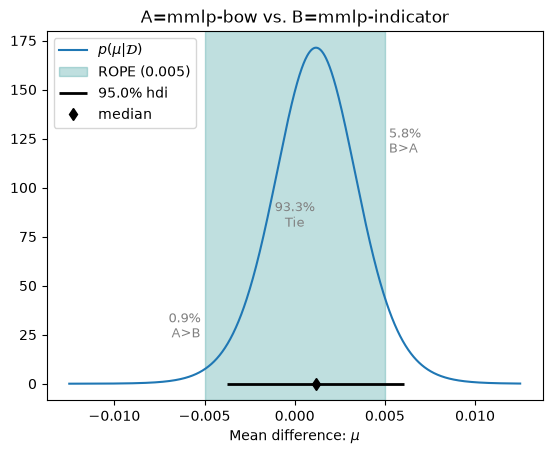

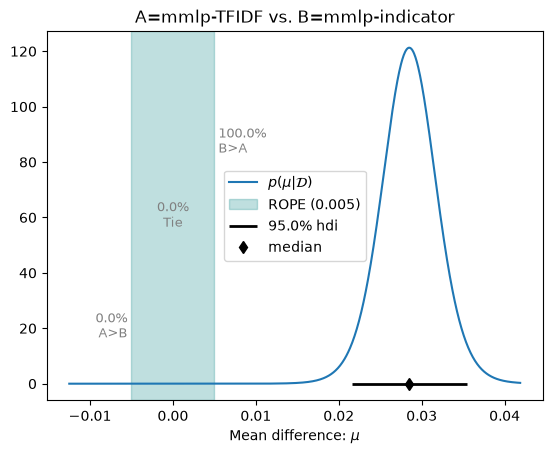

In [24]:
# example plots: representation effect within log-linear, and the extra hidden layer
for pa, pb in [("mmlp-bow", "mmlp-indicator"), ("mmlp-TFIDF", "mmlp-indicator")]:
    if pa in my_classifiers and pb in my_classifiers:
        posterior = part1.analysis.BenavoliCorrelatedT(
            get_all_measurements_for(my_classifiers, pa).flatten(),
            get_all_measurements_for(my_classifiers, pb).flatten(),
            runs=len(my_seeds),
            names=[pa, pb]
        )
        _ = posterior.plot(rope)

## 10. Sources and AI use

* We reused code from the NLP1 tutorial package `part1` (tokenizer training, cross-validation, log-linear and MLP training, Bayesian analysis). We extended `experiment.py`, `smlp.py`, `loglin.py` and `clslib.py` for the nested CV and the two-hidden-layer MLP.
* Benavoli et al. (2017), *Time for a change: a tutorial for comparing multiple classifiers through Bayesian analysis*, JMLR.
* We used AI assistance for debugging and to combine our tasks.